# RL-ABC GitHub quickstart

**Run an end-to-end accelerator beamline optimization directly from the
public RL-ABC repository in Google Colab.**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anwar9Ibrahim/RL-ABC/blob/clean-code-2026/notebooks/RLABC_GitHub_Colab_quickstart.ipynb)

This notebook is a compact user demonstration rather than a
publication-quality benchmark. It:

1. installs Elegant and the SDDS command-line tools;
2. clones the latest commit from the `clean-code-2026` branch;
3. creates a small four-quadrupole FODO example;
4. checks the RL-ABC installation;
5. trains the included DDPG agent for a short run;
6. plots transmission, learned magnet settings, and beam optics.

Repository:
[Anwar9Ibrahim/RL-ABC](https://github.com/Anwar9Ibrahim/RL-ABC/tree/clean-code-2026)

> The default run is intentionally small so that a new user can verify
> the complete software path. Increase the particle count, episode
> budget, and number of independent seeds before drawing scientific
> conclusions.


## What RL-ABC provides

RL-ABC connects standard Elegant inputs to a Gymnasium-compatible
reinforcement-learning environment. It preprocesses the selected
beamline, places diagnostic watch points near controllable elements,
converts simulated particle data into a fixed observation, applies
element-appropriate continuous controls, and computes a
transmission-oriented reward.

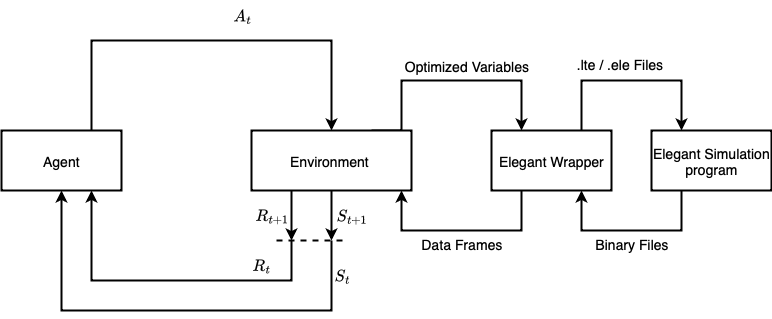

In this quickstart, the included custom DDPG agent tunes the quadrupole
strengths \(K_1\). The same repository also contains a
Stable-Baselines3 entry point and classical optimization baselines.


## Publications

The framework and the simulation-based studies are described in:

1. **A. Ibrahim, F. Ratnikov, M. Kaledin, A. Petrenko, and
   D. Derkach**, “RL-ABC: Reinforcement Learning for Accelerator
   Beamline Control,” arXiv:2604.19146 (2026).
   [arXiv abstract](https://arxiv.org/abs/2604.19146) ·
   [PDF](https://arxiv.org/pdf/2604.19146)

2. **A. Ibrahim, A. Petrenko, M. Kaledin, E. Suleiman, F. Ratnikov,
   and D. Derkach**, “Reinforcement Learning for Accelerator Beamline
   Control: a simulation-based approach,” *International Journal of
   Modern Physics E* **35** (2026), article 2641027.
   [arXiv:2510.26805](https://arxiv.org/abs/2510.26805) ·
   [PDF](https://arxiv.org/pdf/2510.26805) ·
   [journal DOI](https://doi.org/10.1142/S0218301326410272)

3. **A. Ibrahim, D. Derkach, A. Petrenko, F. Ratnikov, and
   M. Kaledin**, “Optimisation of the Accelerator Control by
   Reinforcement Learning: A Simulation-Based Approach,” *Physics of
   Particles and Nuclei* **56**(6), 1476–1481 (2025).
   [arXiv:2503.09665](https://arxiv.org/abs/2503.09665) ·
   [PDF](https://arxiv.org/pdf/2503.09665) ·
   [journal DOI](https://doi.org/10.1134/S1063779625700716)

No final journal DOI is listed for the first item, so this quickstart
links to its arXiv version.


## 1. Runtime options

The defaults provide a short functional demonstration. They are not
intended to reproduce the full experiments reported in the papers.

- `RUN_SMOKE_TEST` checks one RL-ABC decision before training.
- `RUN_TRAINING` runs the short DDPG demonstration.
- `DEMO_EPISODES` controls the training budget.
- `DEMO_PARTICLES` controls the number of simulated particles.
- `RUN_HIGH_STATISTICS` optionally reevaluates the frozen final policy
  using more particles; it does not retrain the policy.


In [ ]:
RUN_SMOKE_TEST = True
RUN_TRAINING = True
DEMO_EPISODES = 20
DEMO_PARTICLES = 200
EVAL_INTERVAL = 5
RUN_HIGH_STATISTICS = False
HIGH_STAT_PARTICLES = 10_000

print({
    "smoke_test": RUN_SMOKE_TEST,
    "training": RUN_TRAINING,
    "episodes": DEMO_EPISODES,
    "particles_per_simulation": DEMO_PARTICLES,
    "high_statistics_evaluation": RUN_HIGH_STATISTICS,
})


## 2. Install Elegant, SDDS, and RL-ABC

Run the following cells in a Linux Google Colab runtime. The source code
is cloned directly from GitHub; Google Drive is not used for the
repository.

The two `gdown` identifiers retrieve the Debian packages for Elegant
2025.2.0 and SDDS Toolkit 5.8. Elegant remains an external simulator,
while RL-ABC calls it during environment transitions.


In [ ]:
# Detect Colab/Linux before running apt commands.
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
IS_LINUX = platform.system().lower() == "linux"

print("Python:", sys.version.split()[0])
print("Operating system:", platform.system())
print("Running in Colab:", IN_COLAB)

if not IS_LINUX:
    raise RuntimeError(
        "The installation cells target Linux/Google Colab. "
        "Open this notebook in Colab to continue."
    )


In [ ]:
# Install system libraries, Elegant, SDDS, gdown, and uv.
#
# The two Google Drive IDs below are the Elegant/SDDS Debian packages
# used by this Colab quickstart. The RL-ABC source itself is cloned
# directly from GitHub.
subprocess.run(
    ["apt-get", "update", "-qq"],
    check=True,
)
subprocess.run(
    [
        "apt-get", "install", "-y", "-qq",
        "libfftw3-3", "liblapacke", "mpich", "wget",
    ],
    check=True,
)
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "gdown", "uv"],
    check=True,
)

downloads = {
    "19v2TnS-MKXjVrvmRp09bF2z9JK4oDQAu": "SDDS Toolkit",
    "1HvEKVeq6Cwsrj13mKguLmt8z_fDWxMY7": "Elegant",
}
for file_id, label in downloads.items():
    print(f"Downloading {label} package...")
    subprocess.run(
        [sys.executable, "-m", "gdown", file_id],
        check=True,
    )

debs = sorted(Path("/content").glob("sddstoolkit_5.8-2_amd64.deb"))
debs += sorted(Path("/content").glob("elegant_2025.2.0-2_amd64.deb"))
if len(debs) != 2:
    raise FileNotFoundError(
        "Expected one SDDS .deb and one Elegant .deb in /content; "
        f"found: {[p.name for p in debs]}"
    )

subprocess.run(
    ["apt-get", "install", "-y", *map(str, debs)],
    check=True,
)

# Elegant uses the RPN definitions file at runtime.
rpn_path = Path("/content/defns.rpn")
if not rpn_path.exists():
    subprocess.run(
        [
            "wget", "-q",
            "https://ops.aps.anl.gov/downloads/defns.rpn",
            "-O", str(rpn_path),
        ],
        check=True,
    )

os.environ["RPN_DEFNS"] = str(rpn_path)
os.environ["HOST_ARCH"] = "linux-x86_64"
os.environ["EPICS_HOST_ARCH"] = "linux-x86_64"

print("Elegant:", shutil.which("elegant"))
print("sdds2stream:", shutil.which("sdds2stream"))
print("RPN definitions:", rpn_path)


In [ ]:
# Clone the current clean-code-2026 branch.
#
# Re-running this cell updates an existing clean clone with a fast-forward
# pull. It does not replace the repository with a Drive copy.
REPO_URL = "https://github.com/Anwar9Ibrahim/RL-ABC.git"
BRANCH = "clean-code-2026"
PROJECT_DIR = Path("/content/RL-ABC")

if not (PROJECT_DIR / ".git").exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "--branch", BRANCH, REPO_URL, str(PROJECT_DIR),
        ],
        check=True,
    )
else:
    subprocess.run(
        ["git", "-C", str(PROJECT_DIR), "checkout", BRANCH],
        check=True,
    )
    subprocess.run(
        ["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"],
        check=True,
    )

commit = subprocess.check_output(
    ["git", "-C", str(PROJECT_DIR), "rev-parse", "HEAD"],
    text=True,
).strip()
print("Using branch:", BRANCH)
print("Commit:", commit)


In [ ]:
# The clean branch is tested with Python 3.10.19. Colab's notebook
# kernel may use a newer Python, so we create a separate Python 3.10
# environment for RL-ABC rather than changing the repository's guard.
VENV_DIR = Path("/content/rlabc-py310")
PY310 = VENV_DIR / "bin/python"

if not PY310.exists():
    subprocess.run(["uv", "python", "install", "3.10"], check=True)
    subprocess.run(
        ["uv", "venv", "--python", "3.10", str(VENV_DIR)],
        check=True,
    )

subprocess.run(
    [
        "uv", "pip", "install",
        "--python", str(PY310),
        "-r", str(PROJECT_DIR / "requirements.txt"),
    ],
    check=True,
)
subprocess.run(
    [
        "uv", "pip", "install",
        "--python", str(PY310), "soliday.sdds",
    ],
    check=True,
)

print(subprocess.check_output(
    [str(PY310), "--version"],
    text=True,
).strip())


### Verify the installation

The next cell checks the external executables and the isolated Python
3.10 environment. It also displays the exact Git commit so a run can be
reproduced later.


In [ ]:
required_commands = ["elegant", "sdds2stream", "sddsquery", "sddsprocess"]
for command in required_commands:
    path = shutil.which(command)
    print(f"{command:12s} -> {path}")
    if path is None:
        raise RuntimeError(f"Missing required command: {command}")

assert Path("/content/defns.rpn").is_file()
assert PY310.is_file()
print("External tool check passed.")


In [ ]:
commit = subprocess.check_output(
    ["git", "-C", str(PROJECT_DIR), "rev-parse", "HEAD"],
    text=True,
).strip()
branch = subprocess.check_output(
    ["git", "-C", str(PROJECT_DIR), "branch", "--show-current"],
    text=True,
).strip()

print("Repository:", REPO_URL)
print("Branch:", branch)
print("Commit:", commit)
print("Project directory:", PROJECT_DIR)


## 3. Select an example beamline

The repository includes the VEPP-5-derived example used by the main
framework study. For a fast first run, this notebook creates a shorter
FODO line with four controllable quadrupoles and a restrictive exit
aperture.

The example is written beside `train.py`; the committed repository files
are not modified.


In [ ]:
# Show the Elegant inputs available in the cloned branch.
repository_inputs = sorted(
    [
        path.relative_to(PROJECT_DIR)
        for pattern in ("*.lte", "*.ele")
        for path in PROJECT_DIR.rglob(pattern)
        if ".venv" not in path.parts
    ],
    key=str,
)

print("Elegant inputs found in the repository:")
for path in repository_inputs[:40]:
    print(" -", path)
if len(repository_inputs) > 40:
    print(f" ... and {len(repository_inputs) - 40} more")


In [ ]:
# Write the small demonstration lattice beside train.py.
#
# Keeping these strings visible makes the notebook self-contained and
# lets users inspect the exact physical system they are controlling.
fodo_lattice = r'''
! Four-quadrupole FODO quickstart beamline
q: charge, total=5.4e-10

AP_ENTRY: MAXAMP, X_MAX=0.025, Y_MAX=0.025, ELLIPTICAL=1
AP_STD:   MAXAMP, X_MAX=0.020, Y_MAX=0.020, ELLIPTICAL=1
AP_TIGHT: MAXAMP, X_MAX=0.008, Y_MAX=0.008, ELLIPTICAL=1

QF1: QUAD, L=0.15, K1=0.0, HKICK=0.0, VKICK=0.0
QD1: QUAD, L=0.15, K1=0.0, HKICK=0.0, VKICK=0.0
QF2: QUAD, L=0.15, K1=0.0, HKICK=0.0, VKICK=0.0
QD2: QUAD, L=0.15, K1=0.0, HKICK=0.0, VKICK=0.0

DR_LONG:  DRIFT, L=0.60
DR_MED:   DRIFT, L=0.40
DR_SHORT: DRIFT, L=0.30

CELL1: LINE=(AP_ENTRY, QF1, DR_LONG, AP_STD, QD1, DR_LONG)
CELL2: LINE=(AP_STD, QF2, DR_LONG, AP_STD, QD2, DR_MED, AP_TIGHT, DR_SHORT)
FODO_LINE: LINE=(CELL1, CELL2)
machine: LINE=(q, FODO_LINE)
'''

fodo_command = r'''
&run_setup
    lattice = elegant_input.lte
    use_beamline = machine
    p_central_mev = 400.0
    sigma = results/%s.sig
    centroid = results/%s.cen
    magnets = results/beamline.mag
    default_order = 2
&end

&twiss_output
    filename = results/twiss.twi
    matched = 0
    beta_x = 2.0
    beta_y = 2.0
&end

&floor_coordinates
    filename = results/xyz.sdds
    include_vertices = 0
    vertices_only = 0
    magnet_centers = 0
&end

&run_control
    n_steps = 1
&end

&bunched_beam
    n_particles_per_bunch = 1000
    emit_nx = 2000.0e-6
    emit_ny = 2000.0e-6
    beta_x = 2.0
    beta_y = 2.0
    sigma_s = 5.0e-3
    sigma_dp = 4e-2
    distribution_type[0] = 3*"gaussian",
    distribution_cutoff[0] = 3*3,
&end

&track
&end
'''

(PROJECT_DIR / "simple_fodo.lte").write_text(
    fodo_lattice.strip() + "\n",
    encoding="utf-8",
)
(PROJECT_DIR / "simple_fodo_track.ele").write_text(
    fodo_command.strip() + "\n",
    encoding="utf-8",
)

print((PROJECT_DIR / "simple_fodo.lte").read_text())


### Automatic preprocessing

RL-ABC parses the selected lattice and introduces diagnostic watch
points used to form consecutive environment observations. The diagram
illustrates the same preprocessing idea on a larger beamline.

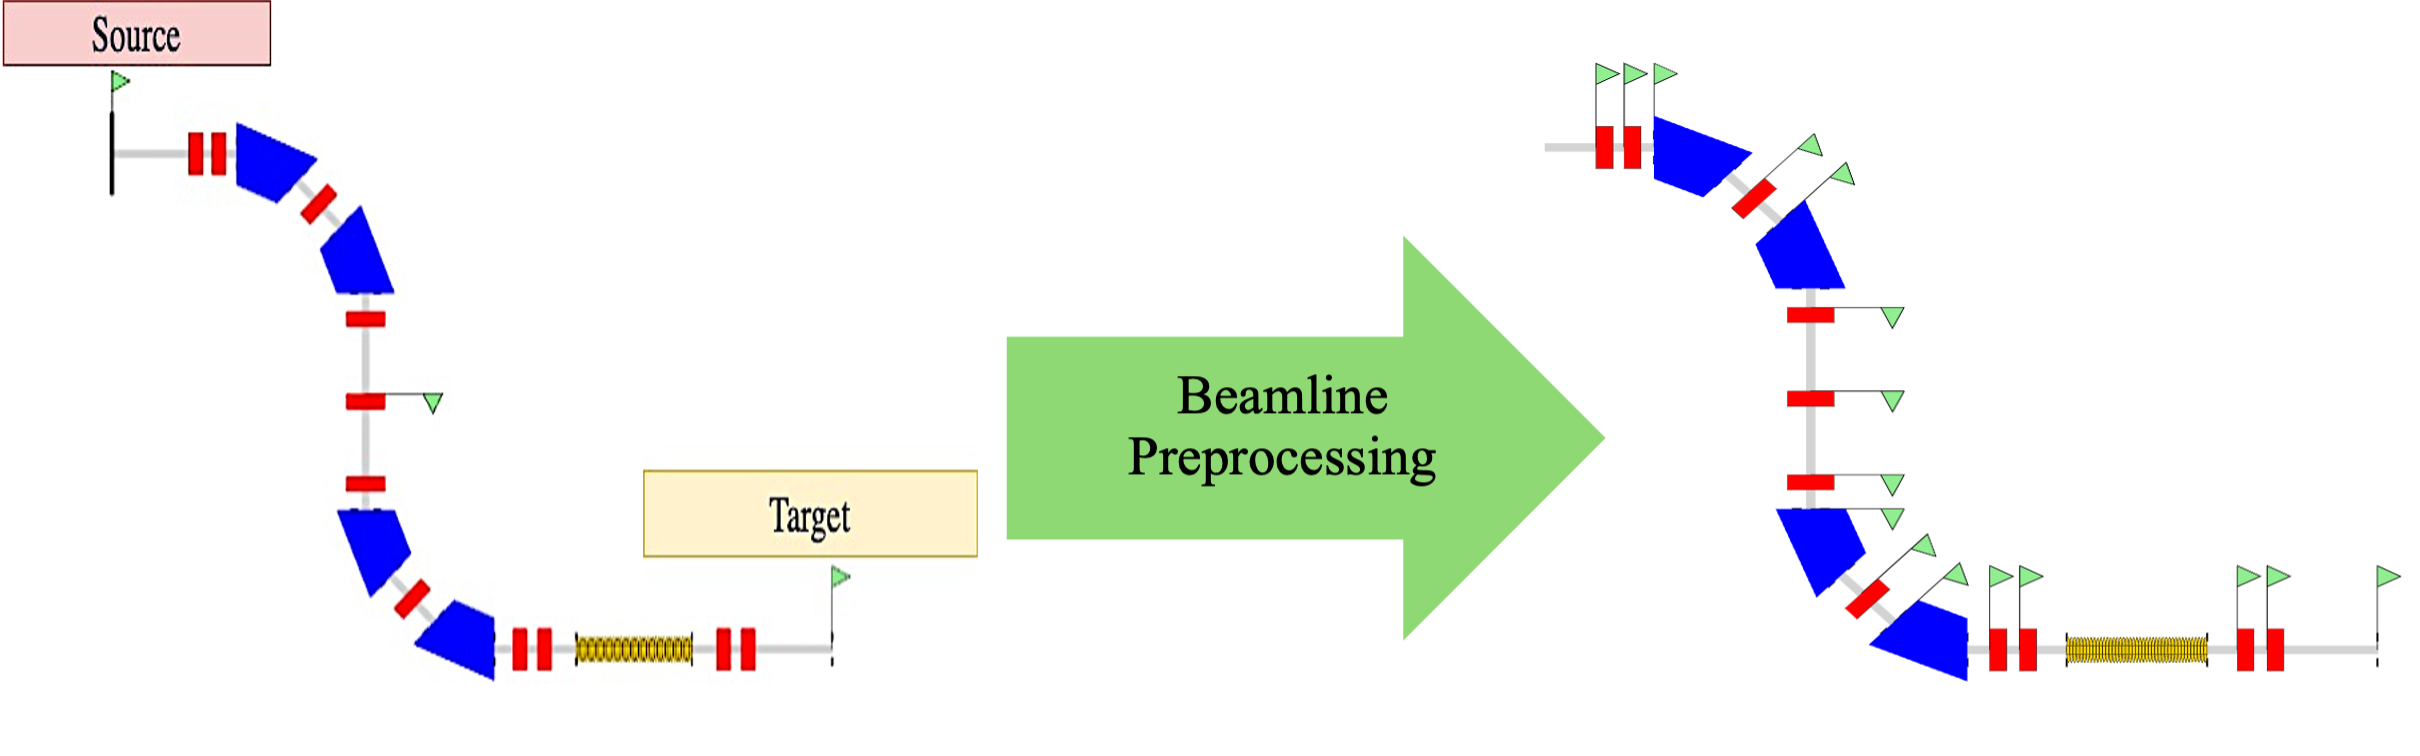


## 4. Configure the demonstration

This generated configuration uses:

- the custom DDPG agent included in the repository;
- the 57-component RL-ABC observation;
- continuous \(K_1\) control for all four quadrupoles;
- one sequential decision per controllable element;
- CPU execution for portability;
- periodic deterministic policy evaluation.

`stage: null` means the whole four-magnet example is active in every
episode. `reset_specific_keys_bool: true` restricts this demonstration
to quadrupole strength rather than the kick components.


In [ ]:
# Create a separate quickstart configuration.
# We leave the repository's committed config.json untouched.
import json

quickstart_config = {
    "platform": {
        "os_type": "linux",
        "elegant_path": "",
        "sdds_path": "/content/defns.rpn",
    },
    "simulation": {
        "override_dynamic_command": False,
        "overridden_command": "elegant",
        "input_beamline_file": "simple_fodo.lte",
        "input_beam_file": "simple_fodo_track",
        "output_beamline_file": "updated_simple_fodo_{seed}.lte",
        "beamline_name": "machine",
        "elegant_input_filename": "elegant_input_fodo_{seed}.lte",
    },
    "environment": {
        "stage": None,
        "n_bins": 5,
        "reset_specific_keys_bool": True,
        "init_num_particles": DEMO_PARTICLES,
    },
    "training": {
        "seed": 0,
        "cpu": True,
        "load_model": False,
        "load_model_tag": "last",
        "n_episodes": DEMO_EPISODES,
        "max_steps": None,
        "greedy": 0.35,
    },
    "buffer": {
        "load_buffer_bool": False,
        "load_buffer_filepath": "quickstart_fodo_buffer_{seed}.pkl",
        "save_buffer_filepath": "quickstart_fodo_buffer_{seed}.pkl",
    },
    "agent": {
        "agent_type": "DDPG",
        "alpha": 0.0001,
        "beta": 0.001,
        "batch_size": 16,
        "gamma": 0.99,
        "tau": 0.005,
        "max_size": 50000,
        "noise_type": "gaussian",
        "log_interval": 20,
        "eval_interval": EVAL_INTERVAL,
        "convert": True,
    },
    "logging": {
        "results_path": "quickstart_results_{seed}/",
        "tb_file_name": "quickstart_fodo_{seed}",
        "logger_file_name": "quickstart_fodo_{seed}.csv",
        "save_model_file_name": "",
        "headers": [
            "reward",
            "initial_number_of_particles",
            "number_of_particles",
            "done",
            "itteration",
            "current_element",
            "dict_vars",
        ],
    },
    "device": {
        "use_gpu": False,
        "use_mps": False,
    },
}

CONFIG_PATH = PROJECT_DIR / "quickstart_fodo.json"
CONFIG_PATH.write_text(
    json.dumps(quickstart_config, indent=2) + "\n",
    encoding="utf-8",
)
print(CONFIG_PATH.read_text())


In [ ]:
# RL-ABC's official setup check validates Python 3.10, input files,
# Elegant, SDDS tools, defns.rpn, and major dependency versions.
setup_check = subprocess.run(
    [
        str(PY310), "train.py",
        "--config", CONFIG_PATH.name,
        "--check-setup",
    ],
    cwd=PROJECT_DIR,
    text=True,
    capture_output=True,
)
print(setup_check.stdout)
print(setup_check.stderr)
if setup_check.returncode != 0:
    raise RuntimeError("RL-ABC setup check failed; inspect the output above.")


### Plot the beamline and Twiss envelope from Elegant output

Both views come from Elegant's generated SDDS files; no element
positions are hard-coded in the plots. The repository's historical
notebook API is implemented by
`rl_framework.visulize.ElegantVisualizer`:

```python
mag_3d = visualizer.env.wrapper.get_mag_3d()
visualizer.env.wrapper.plot_mag_3d(mag_3d)

twiss, htmltwiss = visualizer.plot_twiss()
display(twiss)
```

Because RL-ABC runs in the isolated Python 3.10 environment, the cell
uses the repository's command wrapper to call this API and embeds both
resulting HTML plots in Colab.


In [ ]:
# Generate the layout and Twiss envelope from the same Elegant run.
overview_dir = PROJECT_DIR / "quickstart_overview"
overview_result = subprocess.run(
    [
        str(PY310),
        "-m", "rl_framework.visualization",
        "overview",
        "--config", CONFIG_PATH.name,
        "--output-dir", overview_dir.name,
    ],
    cwd=PROJECT_DIR,
    text=True,
    capture_output=True,
)
if overview_result.stdout:
    print(overview_result.stdout)
if overview_result.returncode != 0:
    raise RuntimeError(
        "Elegant visualization failed.\n\n"
        f"STDOUT:\n{overview_result.stdout}\n"
        f"STDERR:\n{overview_result.stderr}"
    )

from IPython.display import HTML, display

for title, filename in [
    ("Elegant floor-coordinate layout", "layout.html"),
    ("Twiss beam envelope and apertures", "twiss.html"),
]:
    print(title)
    display(HTML(
        (overview_dir / filename).read_text(encoding="utf-8")
    ))


## 5. Run an end-to-end smoke test

The smoke test makes one decision with 100 particles. Passing it verifies
that Python, RL-ABC, Elegant, and SDDS can communicate. It uses a
different seed from the demonstration run so its files do not replace
the main output.


In [ ]:
if RUN_SMOKE_TEST:
    smoke = subprocess.run(
        [
            str(PY310), "train.py",
            "--config", CONFIG_PATH.name,
            "--training.seed", "99",
            "--training.n_episodes", "1",
            "--training.max_steps", "1",
            "--environment.init_num_particles", "100",
            "--agent.batch_size", "2",
            "--agent.max_size", "100",
        ],
        cwd=PROJECT_DIR,
        text=True,
    )
    if smoke.returncode != 0:
        raise RuntimeError("RL-ABC smoke test failed.")
    print("RL-ABC smoke test passed.")
else:
    print("Smoke test skipped.")


## 6. Run the short DDPG demonstration

This run is designed to exercise the complete tool, not to establish
convergence. Elegant performs most of the computation, so this cell may
remain quiet between episode reports.

Existing outputs from an earlier execution are moved into a timestamped
archive before a new run starts.


In [ ]:
# Start a fresh run from the generated quickstart configuration.
#
# If this notebook was run before, archive the previous seed-0 outputs
# first. This prevents stale evaluation files from being mixed with the
# new experiment while keeping the old files recoverable.
from datetime import datetime

previous_outputs = [
    PROJECT_DIR / "quickstart_fodo_0.csv",
    PROJECT_DIR / "quickstart_fodo_buffer_0.pkl",
    PROJECT_DIR / "quickstart_results_0",
    PROJECT_DIR / "models_0",
    PROJECT_DIR / "logs_0",
    PROJECT_DIR / "plots_0",
    PROJECT_DIR / "inputs_0",
    PROJECT_DIR / "observs_0",
    PROJECT_DIR / "summary/quickstart_fodo_0",
    PROJECT_DIR / "ddpg_logger.csv",
    PROJECT_DIR / "ddpg_debug_logger.csv",
]
existing_outputs = [path for path in previous_outputs if path.exists()]
if existing_outputs:
    archive_dir = (
        PROJECT_DIR
        / "quickstart_archives"
        / datetime.now().strftime("%Y%m%d_%H%M%S")
    )
    archive_dir.mkdir(parents=True, exist_ok=True)
    for old_path in existing_outputs:
        destination = archive_dir / old_path.name
        shutil.move(str(old_path), str(destination))
    print("Archived previous run in:", archive_dir)

if RUN_TRAINING:
    train_run = subprocess.run(
        [
            str(PY310), "train.py",
            "--config", CONFIG_PATH.name,
        ],
        cwd=PROJECT_DIR,
        text=True,
    )
    if train_run.returncode != 0:
        raise RuntimeError(
            "Training failed; inspect the output above."
        )
    print("Training and deterministic evaluation completed.")
else:
    print("Training skipped.")


## 7. Inspect the result

The CSV log records the final transition of each episode. The plots
below distinguish noisy training outcomes from periodic deterministic
policy evaluations. With only 20 episodes, substantial run-to-run
fluctuation is normal.


In [ ]:
import numpy as np
import pandas as pd

training_log = PROJECT_DIR / "quickstart_fodo_0.csv"
if not training_log.exists():
    raise FileNotFoundError(training_log)

raw_environment_log = pd.read_csv(training_log)

# The current trainer writes periodic deterministic evaluations to the
# same environment CSV. Reconstruct the DEMO_EPISODES training rows using
# the known one-evaluation-per-EVAL_INTERVAL schedule. Evaluation curves
# are analyzed separately in the next section.
training_row_indices = []
cursor = 0
for episode_number in range(1, DEMO_EPISODES + 1):
    if cursor >= len(raw_environment_log):
        break
    training_row_indices.append(cursor)
    cursor += 1
    if episode_number % EVAL_INTERVAL == 0:
        cursor += 1

training_df = (
    raw_environment_log.iloc[training_row_indices]
    .reset_index(drop=True)
    .copy()
)
training_df["episode"] = np.arange(1, len(training_df) + 1)
training_df["transmission_percent"] = (
    100
    * training_df["number_of_particles"]
    / training_df["initial_number_of_particles"]
)
window = max(3, min(20, len(training_df) // 5))
training_df["rolling_transmission"] = (
    training_df["transmission_percent"]
    .rolling(window, min_periods=1)
    .mean()
)

display(training_df[
    [
        "episode", "reward", "number_of_particles",
        "transmission_percent", "current_element",
    ]
].tail(10))


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(
    training_df["episode"],
    training_df["transmission_percent"],
    color="#93c5fd", alpha=0.65, label="episode",
)
axes[0].plot(
    training_df["episode"],
    training_df["rolling_transmission"],
    color="#1d4ed8", linewidth=2.5,
    label=f"rolling mean (W={window})",
)
axes[0].set(
    title="Training transmission",
    xlabel="Episode",
    ylabel="Particles reaching terminal point (%)",
    ylim=(0, 105),
)
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    training_df["episode"],
    training_df["reward"],
    color="#7c3aed",
)
axes[1].set(
    title="Terminal step reward",
    xlabel="Episode",
    ylabel="Reward",
)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [ ]:
evaluation_rows = []
for path in sorted(
    (PROJECT_DIR / "logs_0").glob("ddpg_eval_*.csv"),
    key=lambda p: int(p.stem.split("_")[-1]),
):
    frame = pd.read_csv(path)
    if frame.empty:
        continue
    final_row = frame.iloc[-1]
    evaluation_rows.append({
        "training_steps": int(path.stem.split("_")[-1]),
        "final_particles": int(final_row["number_of_particles"]),
        "episode_return": float(final_row["episode_reward"]),
        "actions": final_row["actions"],
    })

evaluation_df = pd.DataFrame(evaluation_rows)
if evaluation_df.empty:
    print("No evaluation files were found.")
else:
    evaluation_df["transmission_percent"] = (
        100 * evaluation_df["final_particles"] / DEMO_PARTICLES
    )
    display(evaluation_df[
        [
            "training_steps", "final_particles",
            "transmission_percent", "episode_return",
        ]
    ])

    plt.figure(figsize=(8, 4.5))
    plt.plot(
        evaluation_df["training_steps"],
        evaluation_df["transmission_percent"],
        "o-", color="#059669", linewidth=2,
    )
    plt.ylim(0, 105)
    plt.xlabel("Environment steps")
    plt.ylabel("Deterministic transmission (%)")
    plt.title("Noise-free policy evaluations")
    plt.grid(alpha=0.25)
    plt.show()


In [ ]:
# Extract the final quadrupole strengths without evaluating the log string.
# A regular expression is safer than Python eval().
import re

if not evaluation_df.empty:
    last_actions = str(evaluation_df.iloc[-1]["actions"])
    strengths = {}
    for magnet in ["QF1", "QD1", "QF2", "QD2"]:
        match = re.search(
            rf"'{magnet}K1':\s*(?:np\.float64\()?([-+0-9.eE]+)",
            last_actions,
        )
        strengths[magnet] = float(match.group(1)) if match else np.nan

    display(pd.DataFrame(
        strengths.items(),
        columns=["magnet", "K1 (m^-2)"],
    ))

    plt.figure(figsize=(7, 4))
    bar_colors = [
        "#ef4444" if name.startswith("QF") else "#3b82f6"
        for name in strengths
    ]
    plt.bar(strengths.keys(), strengths.values(), color=bar_colors)
    plt.axhline(0, color="#334155", linewidth=1)
    plt.ylabel("K1 (m$^{-2}$)")
    plt.title("Final deterministic policy settings")
    plt.grid(axis="y", alpha=0.2)
    plt.show()


## 8. Visualize the final simulated beamline

After evaluating the frozen final actor, RL-ABC reads the generated SDDS
output and creates interactive views of:

- the betatron functions;
- dispersion;
- the Twiss beam envelope and apertures;
- the beamline layout.

These plots help distinguish a working software run from a physically
satisfactory solution. Transmission alone does not characterize every
beam-quality objective.


In [ ]:
# Reuse the visualization module shipped by the GitHub branch.
make_visuals = subprocess.run(
    [
        str(PY310),
        "-m", "rl_framework.visualization",
        "policy",
        "--config", CONFIG_PATH.name,
        "--output-dir", "quickstart_visuals",
        "--load-model-tag", "last",
    ],
    cwd=PROJECT_DIR,
    text=True,
    capture_output=True,
)
if make_visuals.stdout:
    print(make_visuals.stdout)
if make_visuals.returncode != 0:
    raise RuntimeError(
        "Policy visualization failed.\n\n"
        f"STDOUT:\n{make_visuals.stdout}\n"
        f"STDERR:\n{make_visuals.stderr}"
    )


In [ ]:
from IPython.display import HTML, display

visual_dir = PROJECT_DIR / "quickstart_visuals"
for title, filename in [
    ("Betatron functions", "betatron.html"),
    ("Dispersion", "dispersion.html"),
    ("Twiss beam envelope and apertures", "twiss.html"),
    ("Magnet layout", "layout.html"),
]:
    path = visual_dir / filename
    print(title)
    if path.exists():
        display(HTML(path.read_text(encoding="utf-8")))
    else:
        print("Missing:", path)


## 9. Optional high-statistics reevaluation

This cell freezes the trained actor and repeats evaluation with more
simulated particles. It can reduce particle-sampling fluctuation for
that selected policy, but it is neither additional training nor an
independent-seed experiment.


In [ ]:
if RUN_HIGH_STATISTICS:
    high_stat = subprocess.run(
        [
            str(PY310), "train.py",
            "--config", CONFIG_PATH.name,
            "--mode", "evaluate",
            "--eval-episodes", "1",
            "--training.load_model", "true",
            "--training.load_model_tag", "last",
            "--environment.init_num_particles", str(HIGH_STAT_PARTICLES),
        ],
        cwd=PROJECT_DIR,
        text=True,
    )
    if high_stat.returncode != 0:
        raise RuntimeError("High-statistics evaluation failed.")
    print("High-statistics evaluation completed.")
else:
    print(
        "Skipped. Set RUN_HIGH_STATISTICS=True after training "
        "to evaluate the frozen policy with more particles."
    )


## 10. Use another Elegant beamline

After the quickstart works, create a copy of the generated JSON
configuration and change the following fields:

```json
{
  "simulation": {
    "input_beamline_file": "your_lattice.lte",
    "input_beam_file": "your_command_without_ele_extension",
    "beamline_name": "your_line_name",
    "output_beamline_file": "updated_lattice_{seed}.lte",
    "elegant_input_filename": "elegant_input_{seed}.lte"
  }
}
```

Place the `.lte` and `.ele` files in the cloned project directory, then
run:

```bash
/content/rlabc-py310/bin/python train.py \
  --config your_config.json --check-setup
```

Before a long run, verify:

- the Elegant command file runs independently;
- `beamline_name` matches a line defined in the lattice;
- the intended quadrupoles/dipoles use element definitions supported by
  the current parser;
- apertures and beam-distribution settings represent the intended task;
- every output path and seed is unique;
- at least one one-step smoke test succeeds.

For a full experiment, use several independent seeds and report the
Elegant-call budget alongside episode counts.


In [ ]:
# Output locations. Download files before the Colab runtime is deleted.
print("Project:", PROJECT_DIR)
print("Generated config:", CONFIG_PATH)
print("Training log:", PROJECT_DIR / "quickstart_fodo_0.csv")
print("Models:", PROJECT_DIR / "models_0")
print("Evaluation logs:", PROJECT_DIR / "logs_0")
print("Visualizations:", PROJECT_DIR / "quickstart_visuals")

# Example:
# from google.colab import files
# files.download(str(PROJECT_DIR / "quickstart_fodo_0.csv"))


## Troubleshooting

| Symptom | Check |
|---|---|
| `elegant` or an SDDS command is missing | Rerun the package-install cell and inspect the `.deb` filenames. |
| `defns.rpn` cannot be found | Confirm `RPN_DEFNS=/content/defns.rpn`. |
| Python version error | Run training with `/content/rlabc-py310/bin/python`, not the notebook kernel. |
| Input-file error | Check the `.lte`, `.ele`, `beamline_name`, and config paths. |
| No evaluation files | Increase `DEMO_EPISODES` or reduce `EVAL_INTERVAL`. |
| Colab session ended | Download logs and checkpoints before the runtime is reclaimed. |

More documentation is available in the cloned repository:

- `README.md`
- `docs/SETUP.md`
- `docs/ELEGANT_INPUT_GUIDE.md`
- `docs/stable_baselines3_guide.md`
- `visualization.ipynb`
- `visualization_high_statistics.ipynb`
